In [1]:

import math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

**PARAMETERS (SEED, MIXTURE WEIGHTS, MEANS, COVARIANCES)**

In [2]:
SEED = 12345
N_PER_CLASS = 1000
K = 3                                   # three Gaussian components per class

# mixture weights and means for the two classes
PI = {0: [0.40, 0.35, 0.25],
      1: [0.30, 0.40, 0.30]}
MU = {0: [[-4, -2], [0, 3], [4, -1]],
      1: [[-3, 3], [1, -3], [5, 3]]}

# covariance matrices C_i (one per component, same for both classes)
C = {
    "spherical": [[[1, 0], [0, 1]], [[1, 0], [0, 1]], [[1, 0], [0, 1]]],
    "diagonal":  [[[2, 0], [0, 0.5]], [[0.5, 0], [0, 2]], [[1.5, 0], [0, 0.7]]],
    "full":      [[[2, 0.8], [0.8, 1]], [[1.5, -0.6], [-0.6, 1]], [[1, 0.5], [0.5, 1.5]]],
}

**RANDOM NUMBER GENERATOR (LCG)**

In [3]:
class LCG:
    """Linear congruential generator (Numerical Recipes constants), uniform in (0, 1)."""
    def __init__(self, seed):
        self.state = seed
        self.a, self.c, self.m = 1664525, 1013904223, 2 ** 32

    def uniform(self):
        self.state = (self.a * self.state + self.c) % self.m
        return (self.state + 0.5) / self.m

**BOX-MULLER AND GMM DATA GENERATION**

In [12]:
# Box-Muller -> two standard normal values
def box_muller(rng):
    u1 = rng.uniform()
    u2 = rng.uniform()
    r = math.sqrt(-2 * math.log(u1))
    return r * math.cos(2 * math.pi * u2), r * math.sin(2 * math.pi * u2)

print(box_muller(LCG(SEED)))

# For C = [[a, b], [b, c]]:  x = mu + L z  with  L = [[sqrt(a), 0], [b/sqrt(a), sqrt(c - b*b/a)]]
# (written by hand, no np.linalg.cholesky)
def generate_point(mean, cov, rng):
    z1, z2 = box_muller(rng)
    a, b, c = cov[0][0], cov[0][1], cov[1][1]
    x = mean[0] + math.sqrt(a) * z1
    y = mean[1] + (b / math.sqrt(a)) * z1 + math.sqrt(c - b * b / a) * z2
    return np.array([x, y])

def generate_class(cls, case, rng):
    X = np.zeros((N_PER_CLASS, 2))
    comp = np.zeros(N_PER_CLASS, dtype=int)
    for n in range(N_PER_CLASS):
        u = rng.uniform()
        if u < PI[cls][0]:                          # mixture-weight ranges
            i = 0
        elif u < PI[cls][0] + PI[cls][1]:
            i = 1
        else:
            i = 2
        X[n] = generate_point(MU[cls][i], C[case][i], rng)
        comp[n] = i
    return X, comp

DATA = {}                      # DATA[case][class] = (points, component labels)
for case in C:
    rng = LCG(SEED)
    DATA[case] = {c: generate_class(c, case, rng) for c in (0, 1)}
    print(case, DATA[case][0][0].shape, DATA[case][1][0].shape)

(2.7749468423937507, 0.2895642870200742)
spherical (1000, 2) (1000, 2)
diagonal (1000, 2) (1000, 2)
full (1000, 2) (1000, 2)


**PLOT GENERATED DATA**

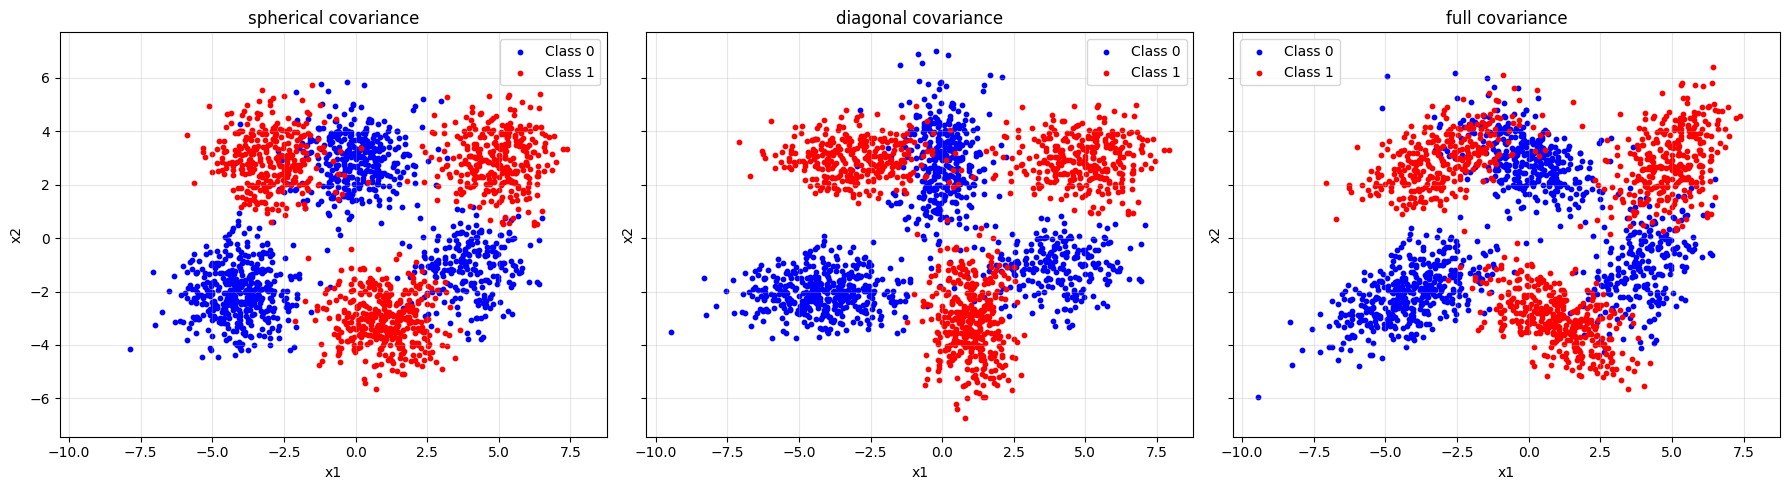

In [5]:
# plot generated data (two classes, different colours, all three covariance types)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, case in zip(axes, DATA):
    ax.scatter(DATA[case][0][0][:, 0], DATA[case][0][0][:, 1], s=10, c="blue", label="Class 0")
    ax.scatter(DATA[case][1][0][:, 0], DATA[case][1][0][:, 1], s=10, c="red", label="Class 1")
    ax.set_title(case + " covariance")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**CALCULATE DISTORTION**

In [6]:
def calculate_distortion(X, model):
    distances = model.transform(X)
    squared_distances = distances ** 2

    cluster_ids = model.predict(X)

    distortion = squared_distances[
        np.arange(len(X)), cluster_ids
    ]

    return distortion

**SPLITTING DATA**

In [7]:
for covariance_name in DATA:

    X0, _ = DATA[covariance_name][0]
    X1, _ = DATA[covariance_name][1]

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    print("\nCovariance:", covariance_name)
    print("Class 0 training:", X0_train.shape)
    print("Class 0 testing:", X0_test.shape)
    print("Class 1 training:", X1_train.shape)
    print("Class 1 testing:", X1_test.shape)


Covariance: spherical
Class 0 training: (800, 2)
Class 0 testing: (200, 2)
Class 1 training: (800, 2)
Class 1 testing: (200, 2)

Covariance: diagonal
Class 0 training: (800, 2)
Class 0 testing: (200, 2)
Class 1 training: (800, 2)
Class 1 testing: (200, 2)

Covariance: full
Class 0 training: (800, 2)
Class 0 testing: (200, 2)
Class 1 training: (800, 2)
Class 1 testing: (200, 2)


**K MEANS CLUSTERING**

In [8]:
def kmeans(X, K, max_iters=100, tolerance=1e-4, random_state=42):

    rng = np.random.default_rng(random_state)

    # 1. Randomly initialize K centroids from the data points
    indices = rng.choice(len(X), size=K, replace=False)
    centroids = X[indices].copy()

    for iteration in range(max_iters):

        # 2. Calculate distances from every point to every centroid
        distances = np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        )

        # 3. Assign each point to its nearest centroid
        labels = np.argmin(distances, axis=1)

        # 4. Calculate new centroids using cluster means
        new_centroids = np.zeros_like(centroids)

        for k in range(K):
            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                new_centroids[k] = np.mean(cluster_points, axis=0)
            else:
                # Reinitialize an empty cluster
                new_centroids[k] = X[rng.integers(len(X))]

        # 5. Check convergence
        movement = np.linalg.norm(new_centroids - centroids)

        centroids = new_centroids

        if movement < tolerance:
            break

    # Reassign points using the final centroids
    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    return centroids, labels, iteration + 1


In [9]:

def plot_cluster_boundaries(X, centroids, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    distances = np.linalg.norm(
        grid[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    labels = np.argmin(
        np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        ),
        axis=1
    )

    plt.figure(figsize=(9, 7))

    plt.contourf(
        xx, yy, regions,
        levels=np.arange(len(centroids) + 1) - 0.5,
        cmap="viridis",
        alpha=0.25
    )

    plt.contour(
        xx, yy, regions,
        levels=np.arange(len(centroids) - 1) + 0.5,
        colors="black",
        linewidths=1.5
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=labels, cmap="viridis",
        s=12, alpha=0.7
    )

    plt.scatter(
        centroids[:, 0], centroids[:, 1],
        c="red", marker="X", s=200,
        edgecolors="black",
        label="Centroids"
    )

    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()


**PLOTS**


Covariance: spherical
Class 0 test average distortion: 2.1621
Class 1 test average distortion: 2.1078
Accuracy: 95.75 %
Confusion matrix:
[[188  12]
 [  5 195]]


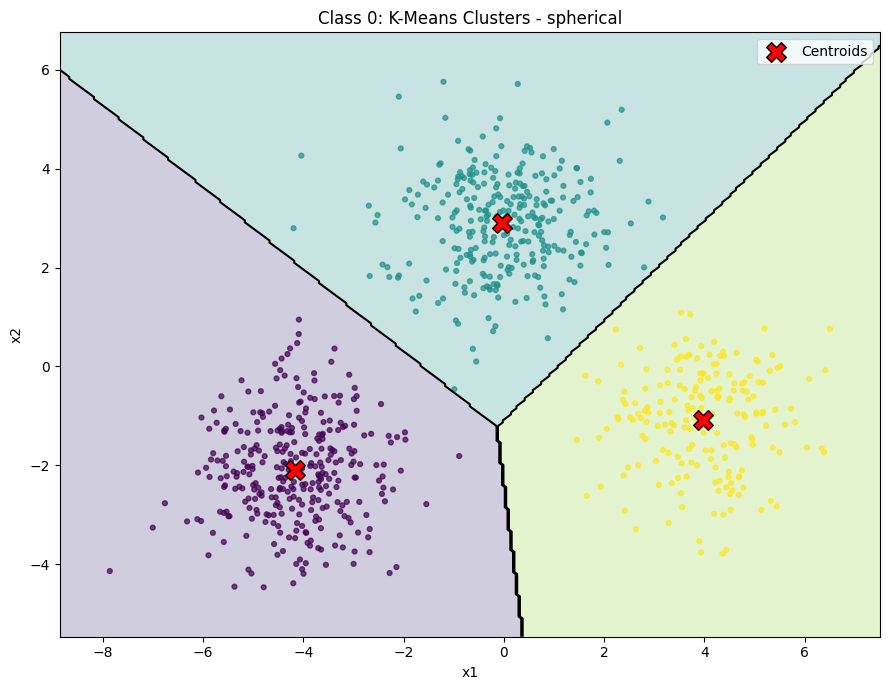

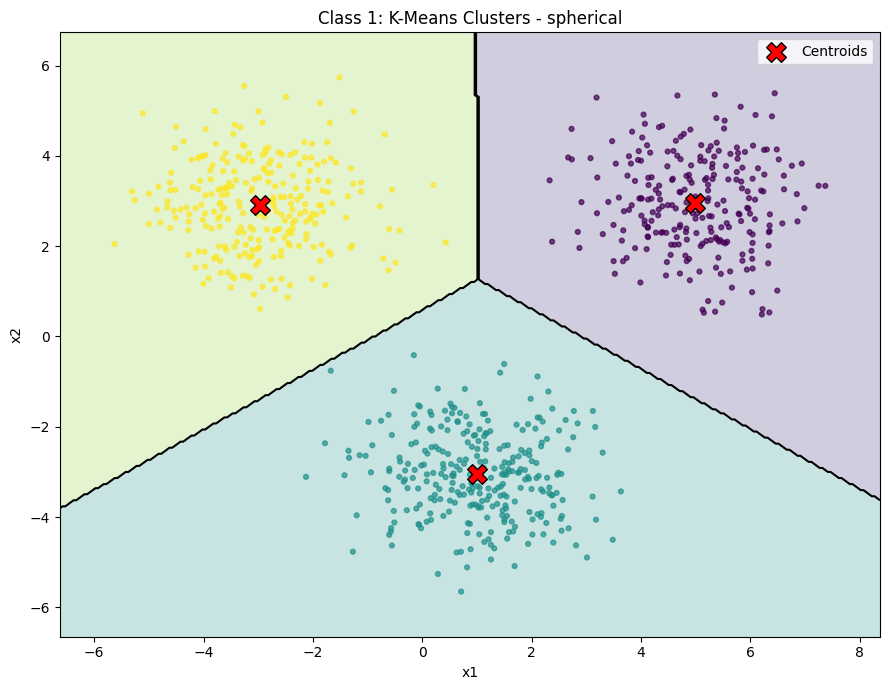


Covariance: diagonal
Class 0 test average distortion: 2.761
Class 1 test average distortion: 2.5341
Accuracy: 93.75 %
Confusion matrix:
[[191   9]
 [ 16 184]]


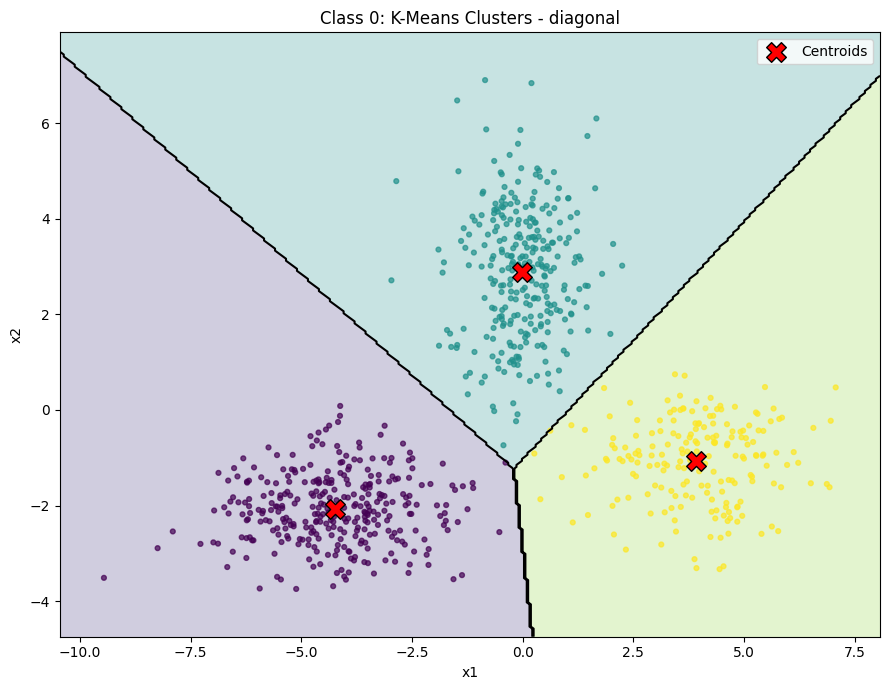

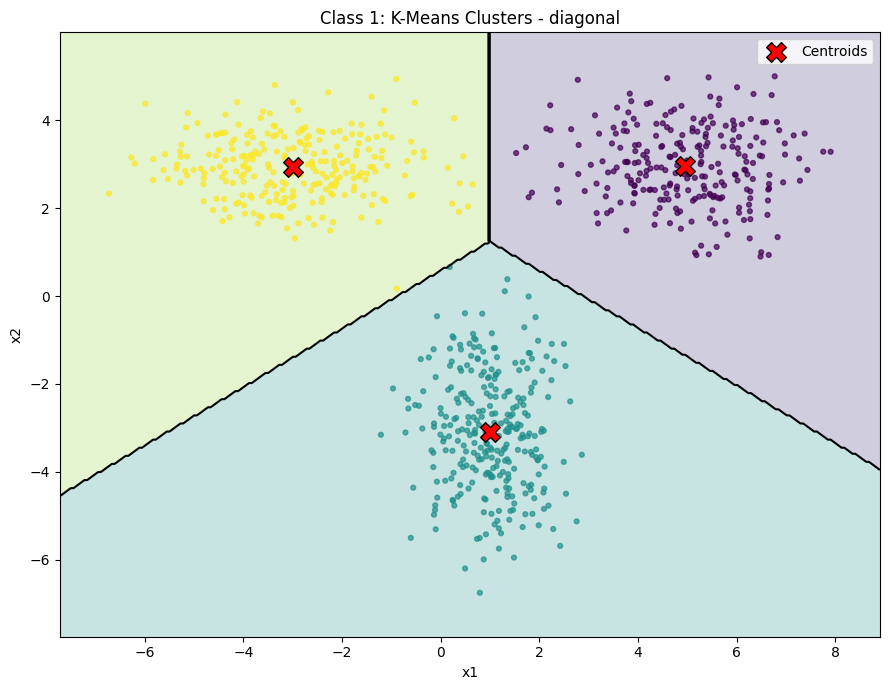


Covariance: full
Class 0 test average distortion: 2.9072
Class 1 test average distortion: 2.788
Accuracy: 90.25 %
Confusion matrix:
[[176  24]
 [ 15 185]]


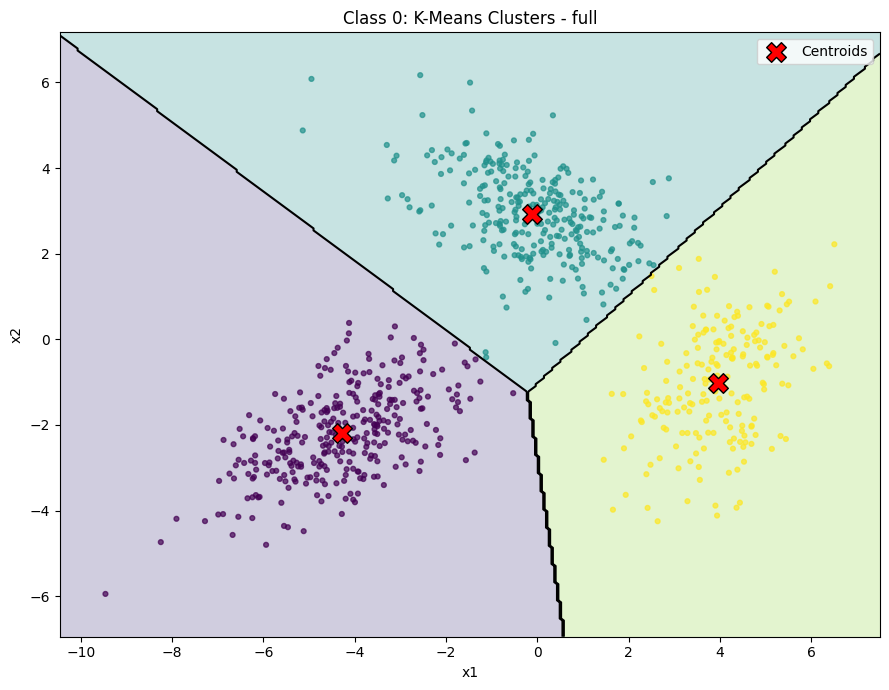

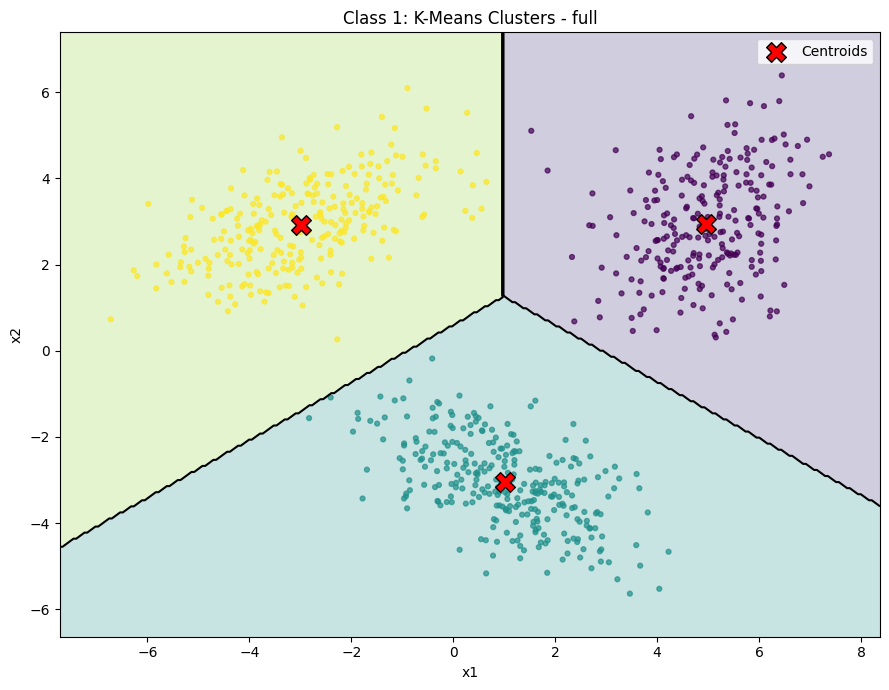

In [10]:
for covariance_name in DATA:

    X0, _ = DATA[covariance_name][0]
    X1, _ = DATA[covariance_name][1]

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    centroids0, _, _ = kmeans(
        X0_train, K, random_state=42
    )

    centroids1, _, _ = kmeans(
        X1_train, K, random_state=42
    )

    X_test = np.vstack([X0_test, X1_test])

    y_test = np.concatenate([
        np.zeros(len(X0_test), dtype=int),
        np.ones(len(X1_test), dtype=int)
    ])

    def calculate_distortion(X, centroids):
        distances = np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        )

        squared_distances = distances ** 2

        nearest_distances = np.min(squared_distances, axis=1)

        return nearest_distances

    d0 = calculate_distortion(X_test, centroids0)
    d1 = calculate_distortion(X_test, centroids1)

    y_pred = (d1 < d0).astype(int)

    accuracy = accuracy_score(y_test, y_pred)

    print("\nCovariance:", covariance_name)

    print(
        "Class 0 test average distortion:",
        round(np.mean(d0[y_test == 0]), 4)
    )

    print(
        "Class 1 test average distortion:",
        round(np.mean(d1[y_test == 1]), 4)
    )

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    plot_cluster_boundaries(
    X0_train,
    centroids0,
    f"Class 0: K-Means Clusters - {covariance_name}"
    )

    plot_cluster_boundaries(
        X1_train,
        centroids1,
        f"Class 1: K-Means Clusters - {covariance_name}"
    )


